<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# Model Evaluation and Refinement


Estimated time needed: **30** minutes
    

## Objectives

After completing this lab you will be able to:

* Evaluate and refine prediction models
* Identify overfitting and underfittin of models
* Perform Ridge regression for polynomial feature models
* Use Grid search to identify best choice of hyperparameters


<h2>Table of Contents</h2>
<ul>
    <li><a href="#ref1">Model Evaluation </a></li>
    <li><a href="#ref2">Over-fitting, Under-fitting and Model Selection </a></li>
    <li><a href="#ref3">Ridge Regression </a></li>
    <li><a href="#ref4">Grid Search</a></li>
</ul>


This dataset was hosted on IBM Cloud object. Click <a href="https://cocl.us/DA101EN_object_storage">HERE</a> for free storage.


In [1]:
#install specific version of libraries used in lab
#! mamba install pandas==1.3.3 -y
#! mamba install numpy=1.21.2 -y
#! mamba install sklearn=0.20.1 -y
#! mamba install   ipywidgets=7.4.2 -y

In [2]:
#Install libraries
%pip install pandas matplotlib scipy scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np

# Import clean data 
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/module_5_auto.csv'
df = pd.read_csv(path)

In [4]:
df.to_csv('module_5_auto.csv')

 First, let's only use numeric data:


In [5]:
df=df._get_numeric_data()
df.head()

,Unnamed: 0.1,Unnamed: 0,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,...,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
0,0,0,3,122,88.6,0.811148,0.890278,48.8,2548,130,...,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,0,1
1,1,1,3,122,88.6,0.811148,0.890278,48.8,2548,130,...,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,0,1
2,2,2,1,122,94.5,0.822681,0.909722,52.4,2823,152,...,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,0,1
3,3,3,2,164,99.8,0.848630,0.919444,54.3,2337,109,...,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,0,1
4,4,4,2,164,99.4,0.848630,0.922222,54.3,2824,136,...,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,0,1


<h2>Functions for Plotting</h2>
First, we import the seaborn and matplotlib library for plotting.


In [6]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

Now, we define the functions that will be used in the lab for making plots at different stages.


In [7]:
def DistributionPlot(RedFunction, BlueFunction, RedName, BlueName, Title):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))

    ax1 = sns.kdeplot(RedFunction, color="r", label=RedName)
    ax2 = sns.kdeplot(BlueFunction, color="b", label=BlueName, ax=ax1)

    plt.title(Title)
    plt.xlabel('Price (in dollars)')
    plt.ylabel('Proportion of Cars')
    plt.show()
    plt.close()

In [8]:
def PollyPlot(xtrain, xtest, y_train, y_test, lr,poly_transform):
    width = 12
    height = 10
    plt.figure(figsize=(width, height))
    
    
    #training data 
    #testing data 
    # lr:  linear regression object 
    #poly_transform:  polynomial transformation object 
 
    xmax=max([xtrain.values.max(), xtest.values.max()])

    xmin=min([xtrain.values.min(), xtest.values.min()])

    x=np.arange(xmin, xmax, 0.1)


    plt.plot(xtrain, y_train, 'ro', label='Training Data')
    plt.plot(xtest, y_test, 'go', label='Test Data')
    plt.plot(x, lr.predict(poly_transform.fit_transform(x.reshape(-1, 1))), label='Predicted Function')
    plt.ylim([-10000, 60000])
    plt.ylabel('Price')
    plt.legend()

<h2 id="ref1">Part 1: Training and Testing</h2>

<p>An important step in testing your model is to split your data into training and testing data. We will place the target data <b>price</b> in a separate dataframe <b>y_data</b>:</p>


In [9]:
y_data = df['price']

Drop price data in dataframe **x_data**:


In [10]:
x_data=df.drop('price',axis=1)

Now, we randomly split our data into training and testing data using the function <b>train_test_split</b>. 


In [11]:
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.10, random_state=1)


print("number of test samples :", x_test.shape[0])
print("number of training samples:",x_train.shape[0])


number of test samples : 21
number of training samples: 180


The <b>test_size</b> parameter sets the proportion of data that is split into the testing set. In the above, the testing set is 10% of the total dataset. 


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #1):</h1>

<b>Use the function "train_test_split" to split up the dataset such that 40% of the data samples will be utilized for testing. Set the parameter "random_state" equal to zero. The output of the function should be the following:  "x_train1" , "x_test1", "y_train1" and  "y_test1".</b>
</div>


In [12]:
# Write your code below and press Shift+Enter to execute 
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0) 
print("number of test samples :", x_test1.shape[0])
print("number of training samples:",x_train1.shape[0])

number of test samples : 81
number of training samples: 120


<details><summary>Click here for the solution</summary>

```python
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0) 
print("number of test samples :", x_test1.shape[0])
print("number of training samples:",x_train1.shape[0])
```

</details>


Let's import <b>LinearRegression</b> from the module <b>linear_model</b>.


In [13]:
from sklearn.linear_model import LinearRegression

 We create a Linear Regression object:


In [14]:
lre=LinearRegression()

We fit the model using the feature "horsepower":


In [15]:
lre.fit(x_train[['horsepower']], y_train)

LinearRegression()

Let's calculate the R^2 on the test data:


In [16]:
lre.score(x_test[['horsepower']], y_test)

0.3635875575078824

We can see the R^2 is much smaller using the test data compared to the training data.


In [17]:
lre.score(x_train[['horsepower']], y_train)

0.6619724197515103

<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #2): </h1>
<b> 
Find the R^2  on the test data using 40% of the dataset for testing.
</b>
</div>


In [18]:
# Write your code below and press Shift+Enter to execute 
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0)
lre.fit(x_train1[['horsepower']],y_train1)
lre.score(x_test1[['horsepower']],y_test1)

0.7139364665406973

<details><summary>Click here for the solution</summary>

```python
x_train1, x_test1, y_train1, y_test1 = train_test_split(x_data, y_data, test_size=0.4, random_state=0)
lre.fit(x_train1[['horsepower']],y_train1)
lre.score(x_test1[['horsepower']],y_test1)

```

</details>


Sometimes you do not have sufficient testing data; as a result, you may want to perform cross-validation. Let's go over several methods that you can use for cross-validation. 


<h2>Cross-Validation Score</h2>


Let's import <b>cross_val_score</b> from the module <b>model_selection</b>.


In [19]:
from sklearn.model_selection import cross_val_score

We input the object, the feature ("horsepower"), and the target data (y_data). The parameter 'cv' determines the number of folds. In this case, it is 4. 


In [20]:
Rcross = cross_val_score(lre, x_data[['horsepower']], y_data, cv=4)

The default scoring is R^2. Each element in the array has the average R^2 value for the fold:


In [21]:
Rcross

array([0.7746232 , 0.51716687, 0.74785353, 0.04839605])

 We can calculate the average and standard deviation of our estimate:


In [22]:
print("The mean of the folds are", Rcross.mean(), "and the standard deviation is" , Rcross.std())

The mean of the folds are 0.5220099150421194 and the standard deviation is 0.2911839444756025


We can use negative squared error as a score by setting the parameter  'scoring' metric to 'neg_mean_squared_error'. 


In [23]:
-1 * cross_val_score(lre,x_data[['horsepower']], y_data,cv=4,scoring='neg_mean_squared_error')

array([20254142.84026704, 43745493.26505169, 12539630.34014931,
       17561927.72247589])

<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #3): </h1>
<b> 
Calculate the average R^2 using two folds, then find the average R^2 for the second fold utilizing the "horsepower" feature: 
</b>
</div>


In [24]:
# Write your code below and press Shift+Enter to execute 
Rc=cross_val_score(lre,x_data[['horsepower']], y_data,cv=2)
Rc.mean()

0.5166761697127429

<details><summary>Click here for the solution</summary>

```python
Rc=cross_val_score(lre,x_data[['horsepower']], y_data,cv=2)
Rc.mean()

```

</details>


You can also use the function 'cross_val_predict' to predict the output. The function splits up the data into the specified number of folds, with one fold for testing and the other folds are used for training. First, import the function:


In [25]:
from sklearn.model_selection import cross_val_predict

We input the object, the feature <b>"horsepower"</b>, and the target data <b>y_data</b>. The parameter 'cv' determines the number of folds. In this case, it is 4. We can produce an output:


In [26]:
yhat = cross_val_predict(lre,x_data[['horsepower']], y_data,cv=4)
yhat[0:5]

array([14141.63807508, 14141.63807508, 20814.29423473, 12745.03562306,
       14762.35027598])

<h2 id="ref2">Part 2: Overfitting, Underfitting and Model Selection</h2>

<p>It turns out that the test data, sometimes referred to as the "out of sample data", is a much better measure of how well your model performs in the real world.  One reason for this is overfitting.

Let's go over some examples. It turns out these differences are more apparent in Multiple Linear Regression and Polynomial Regression so we will explore overfitting in that context.</p>


Let's create Multiple Linear Regression objects and train the model using <b>'horsepower'</b>, <b>'curb-weight'</b>, <b>'engine-size'</b> and <b>'highway-mpg'</b> as features.


In [27]:
lr = LinearRegression()
lr.fit(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_train)

LinearRegression()

Prediction using training data:


In [28]:
yhat_train = lr.predict(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
yhat_train[0:5]

array([ 7426.6731551 , 28323.75090803, 14213.38819709,  4052.34146983,
       34500.19124244])

Prediction using test data: 


In [29]:
yhat_test = lr.predict(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
yhat_test[0:5]

array([11349.35089149,  5884.11059106, 11208.6928275 ,  6641.07786278,
       15565.79920282])

Let's perform some model evaluation using our training and testing data separately. 


Let's examine the distribution of the predicted values of the training data.


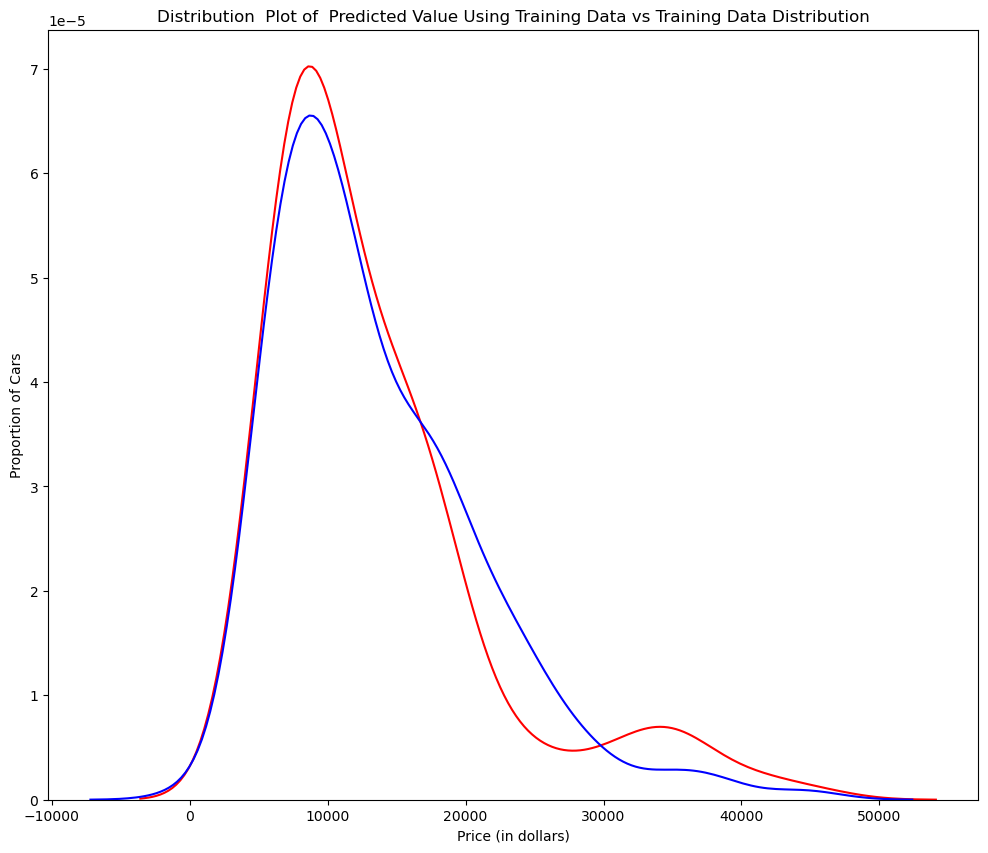

In [30]:
Title = 'Distribution  Plot of  Predicted Value Using Training Data vs Training Data Distribution'
DistributionPlot(y_train, yhat_train, "Actual Values (Train)", "Predicted Values (Train)", Title)

Figure 1: Plot of predicted values using the training data compared to the actual values of the training data. 


So far, the model seems to be doing well in learning from the training dataset. But what happens when the model encounters new data from the testing dataset? When the model generates new values from the test data, we see the distribution of the predicted values is much different from the actual target values. 


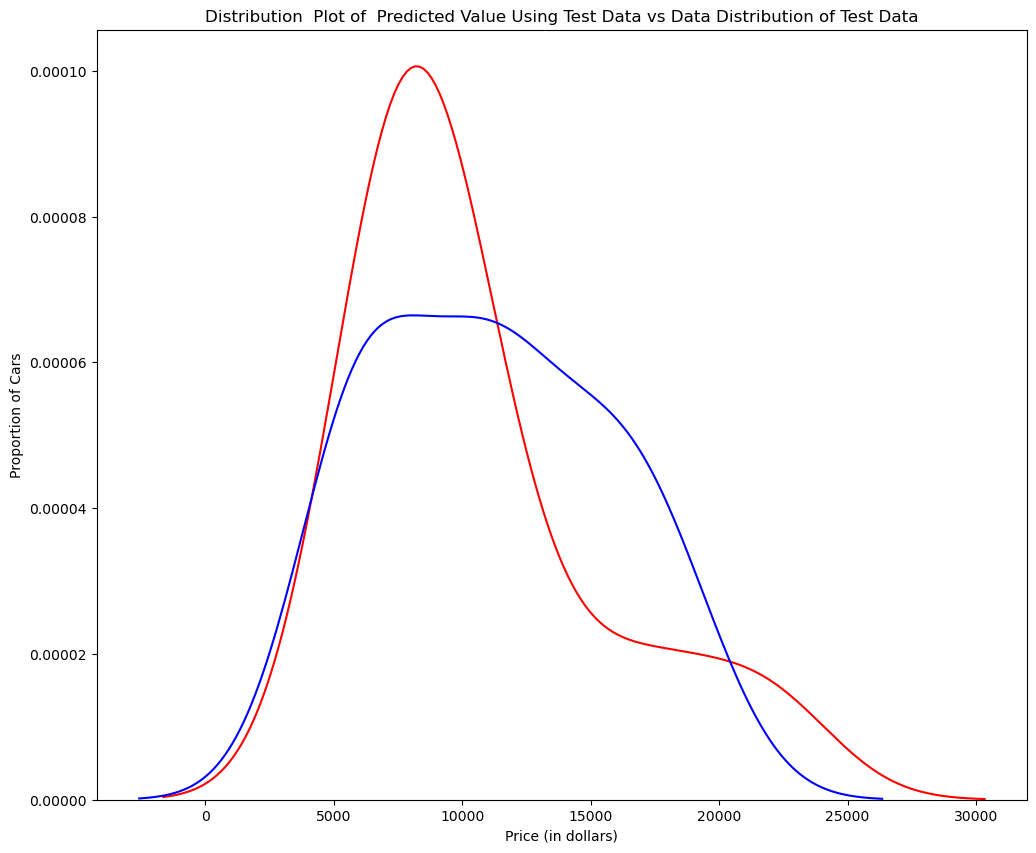

In [31]:
Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'
DistributionPlot(y_test,yhat_test,"Actual Values (Test)","Predicted Values (Test)",Title)

Figure 2: Plot of predicted value using the test data compared to the actual values of the test data. 


<p>Comparing Figure 1 and Figure 2, it is evident that the distribution of the test data in Figure 1 is much better at fitting the data. This difference in Figure 2 is apparent in the range of 5000 to 15,000. This is where the shape of the distribution is extremely different. Let's see if polynomial regression also exhibits a drop in the prediction accuracy when analysing the test dataset.</p>


In [32]:
from sklearn.preprocessing import PolynomialFeatures

<h4>Overfitting</h4>
<p>Overfitting occurs when the model fits the noise, but not the underlying process. Therefore, when testing your model using the test set, your model does not perform as well since it is modelling noise, not the underlying process that generated the relationship. Let's create a degree 5 polynomial model.</p>


Let's use 55 percent of the data for training and the rest for testing:


In [33]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.45, random_state=0)

We will perform a degree 5 polynomial transformation on the feature <b>'horsepower'</b>. 


In [34]:
pr = PolynomialFeatures(degree=5)
x_train_pr = pr.fit_transform(x_train[['horsepower']])
x_test_pr = pr.fit_transform(x_test[['horsepower']])
pr

PolynomialFeatures(degree=5)

Now, let's create a Linear Regression model "poly" and train it.


In [35]:
poly = LinearRegression()
poly.fit(x_train_pr, y_train)

LinearRegression()

We can see the output of our model using the method "predict." We assign the values to "yhat".


In [36]:
yhat = poly.predict(x_test_pr)
yhat[0:5]

array([ 6728.73877623,  7308.06173582, 12213.81078747, 18893.1290908 ,
       19995.81407813])

Let's take the first five predicted values and compare it to the actual targets. 


In [37]:
print("Predicted values:", yhat[0:4])
print("True values:", y_test[0:4].values)

Predicted values: [ 6728.73877623  7308.06173582 12213.81078747 18893.1290908 ]
True values: [ 6295. 10698. 13860. 13499.]


We will use the function "PollyPlot" that we defined at the beginning of the lab to display the training data, testing data, and the predicted function.


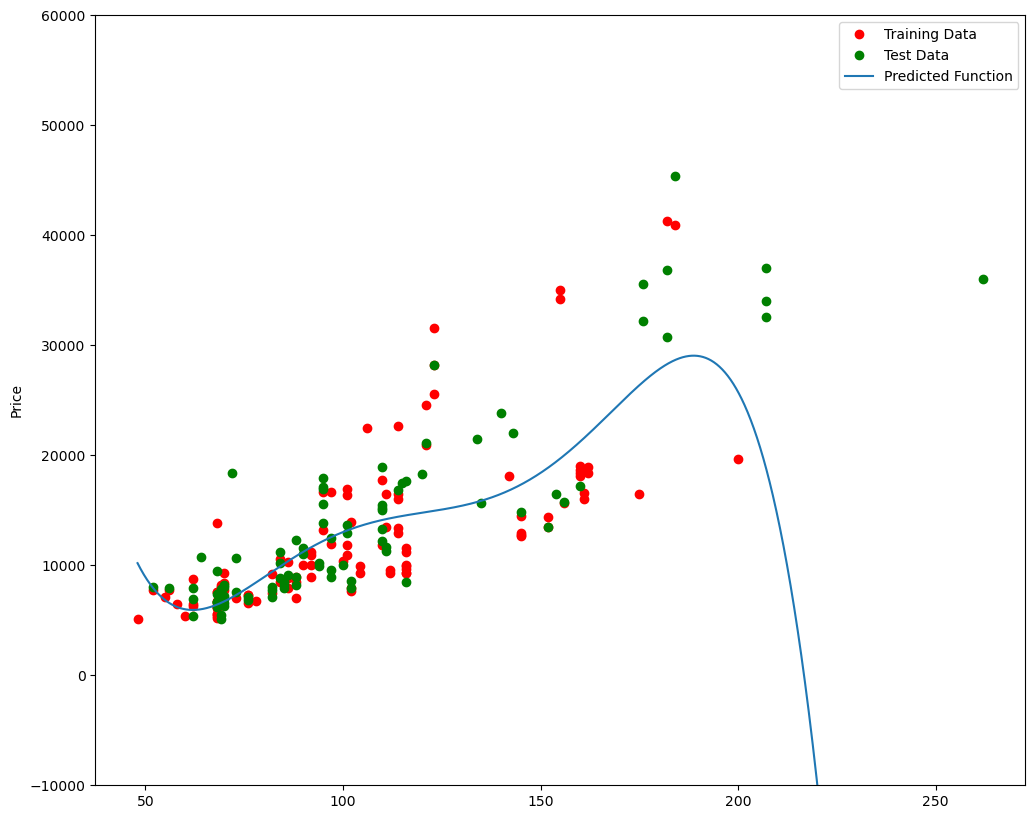

In [38]:
PollyPlot(x_train['horsepower'], x_test['horsepower'], y_train, y_test, poly,pr)

Figure 3: A polynomial regression model where red dots represent training data, green dots represent test data, and the blue line represents the model prediction. 


We see that the estimated function appears to track the data but around 200 horsepower, the function begins to diverge from the data points. 


 R^2 of the training data:


In [39]:
poly.score(x_train_pr, y_train)

0.5567716902028981

 R^2 of the test data:


In [40]:
poly.score(x_test_pr, y_test)

-29.871621329672777

We see the R^2 for the training data is 0.5567 while the R^2 on the test data was -29.87.  The lower the R^2, the worse the model. A negative R^2 is a sign of overfitting.


Let's see how the R^2 changes on the test data for different order polynomials and then plot the results:


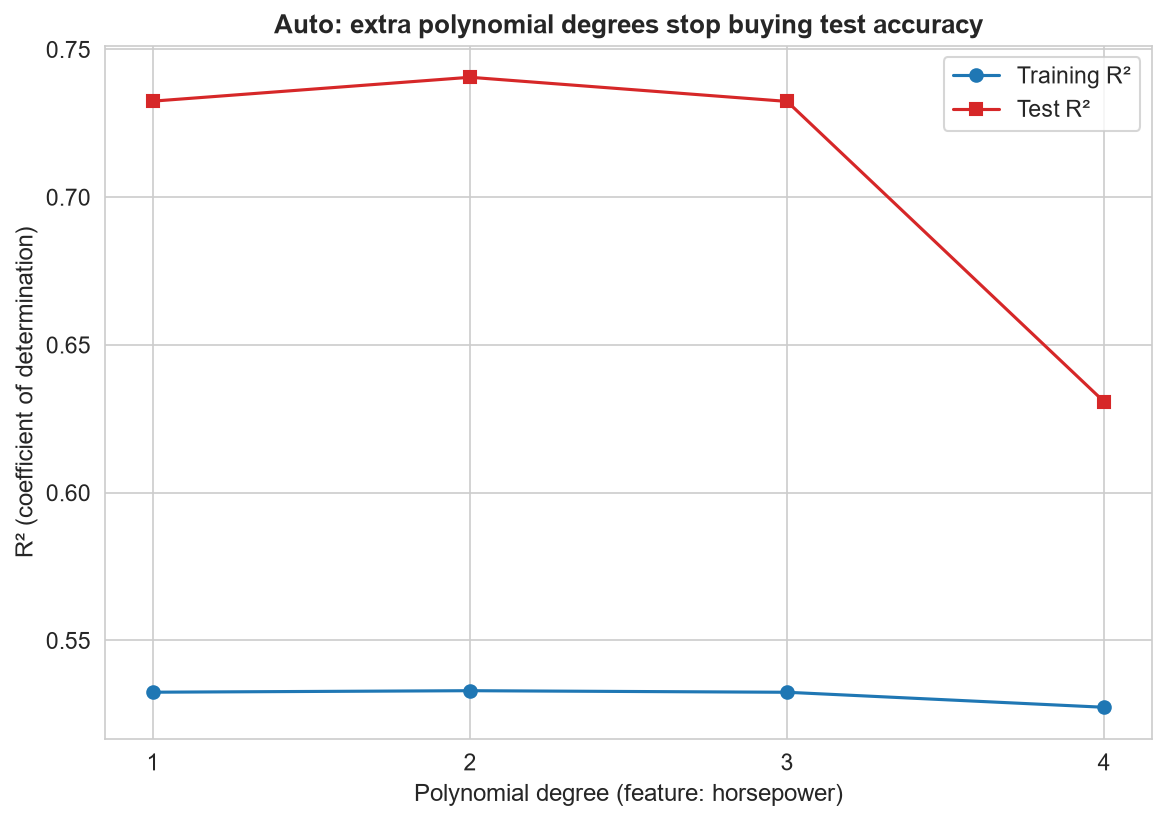

In [41]:
Rsqu_test = []
Rsqu_train = []

order = [1, 2, 3, 4]
for n in order:
    pr = PolynomialFeatures(degree=n)

    x_train_pr = pr.fit_transform(x_train[['horsepower']])

    x_test_pr = pr.fit_transform(x_test[['horsepower']])

    lr.fit(x_train_pr, y_train)

    Rsqu_train.append(lr.score(x_train_pr, y_train))
    Rsqu_test.append(lr.score(x_test_pr, y_test))

plt.plot(order, Rsqu_train, 'o-', label='Training R²')
plt.plot(order, Rsqu_test, 's-', label='Test R²')
plt.xticks(order)
plt.xlabel('Polynomial degree (feature: horsepower)')
plt.ylabel('R² (coefficient of determination)')
plt.title('Auto: extra polynomial degrees stop buying test accuracy')
plt.legend()

We see the R^2 gradually increases until an order three polynomial is used. Then, the R^2 dramatically decreases at an order four polynomial.


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4a):</h1>

<b>We can perform polynomial transformations with more than one feature. Create a "PolynomialFeatures" object "pr1" of degree two.</b>
</div>


In [42]:
# Write your code below and press Shift+Enter to execute 
pr1=PolynomialFeatures(degree=2)
pr1

PolynomialFeatures()

<details><summary>Click here for the solution</summary>

```python
pr1=PolynomialFeatures(degree=2)

```

</details>


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4b): </h1>

<b> 
 Transform the training and testing samples for the features 'horsepower', 'curb-weight', 'engine-size' and 'highway-mpg'. Hint: use the method "fit_transform".</b>
</div>


In [43]:
# Write your code below and press Shift+Enter to execute 
x_train_pr1=pr1.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
x_test_pr1=pr1.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
print("shape of the transformed training set:", x_train_pr1.shape)
print("shape of the transformed test set    :", x_test_pr1.shape)

shape of the transformed training set: (110, 15)
shape of the transformed test set    : (91, 15)


<details><summary>Click here for the solution</summary>

```python
x_train_pr1=pr1.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

x_test_pr1=pr1.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])


```

</details>


<!-- The answer is below:

x_train_pr1=pr.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])
x_test_pr1=pr.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']])

-->


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4c): </h1>
<b> 
How many dimensions does the new feature have? Hint: use the attribute "shape".
</b>
</div>


In [44]:
# Write your code below and press Shift+Enter to execute 
x_train_pr1.shape #there are now 15 features

(110, 15)

<details><summary>Click here for the solution</summary>

```python
x_train_pr1.shape #there are now 15 features


```

</details>


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4d): </h1>

<b> 
Create a linear regression model "poly1". Train the object using the method "fit" using the polynomial features.</b>
</div>


In [45]:
# Write your code below and press Shift+Enter to execute 
poly1=LinearRegression().fit(x_train_pr1,y_train)
poly1

LinearRegression()

<details><summary>Click here for the solution</summary>

```python
poly1=LinearRegression().fit(x_train_pr1,y_train)


```

</details>


 <div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4e): </h1>
<b>Use the method  "predict" to predict an output on the polynomial features, then use the function "DistributionPlot" to display the distribution of the predicted test output vs. the actual test data.</b>
</div>


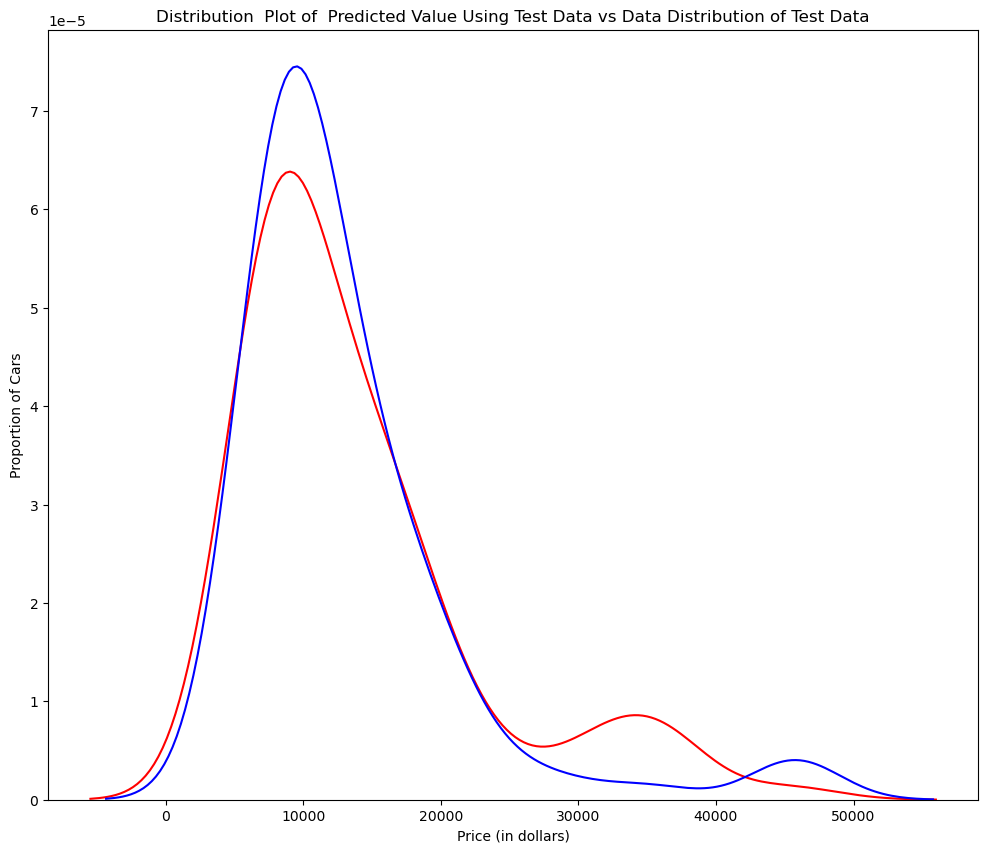

In [46]:
# Write your code below and press Shift+Enter to execute 
yhat_test1=poly1.predict(x_test_pr1)

Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'

DistributionPlot(y_test, yhat_test1, "Actual Values (Test)", "Predicted Values (Test)", Title)

<details><summary>Click here for the solution</summary>

```python
yhat_test1=poly1.predict(x_test_pr1)

Title='Distribution  Plot of  Predicted Value Using Test Data vs Data Distribution of Test Data'

DistributionPlot(y_test, yhat_test1, "Actual Values (Test)", "Predicted Values (Test)", Title)

```

</details>


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #4f): </h1>

<b>Using the distribution plot above, describe (in words) the two regions where the predicted prices are less accurate than the actual prices.</b>
</div>


In [47]:
# Write your code below and press Shift+Enter to execute 
# The predicted value is higher than the actual value for cars in the $10,000 price range, whereas
# the predicted price is lower than the actual price in the $30,000 to $40,000 range. As such the
# model is not as accurate in these two regions.

<details><summary>Click here for the solution</summary>

```python
#The predicted value is higher than actual value for cars where the price $10,000 range, conversely the predicted price is lower than the price cost in the $30,000 to $40,000 range. As such the model is not as accurate in these ranges.

```

</details>



<h2 id="ref3">Part 3: Ridge Regression</h2> 


 In this section, we will review Ridge Regression and see how the parameter alpha changes the model. Just a note, here our test data will be used as validation data.


 Let's perform a degree two polynomial transformation on our data. 


In [48]:
pr=PolynomialFeatures(degree=2)
x_train_pr=pr.fit_transform(x_train[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])
x_test_pr=pr.fit_transform(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg','normalized-losses','symboling']])

 Let's import  <b>Ridge</b>  from the module <b>linear models</b>.


In [49]:
from sklearn.linear_model import Ridge

Let's create a Ridge regression object, setting the regularization parameter (alpha) to 1 


In [50]:
RigeModel=Ridge(alpha=1)

Like regular regression, you can fit the model using the method <b>fit</b>.


In [51]:
RigeModel.fit(x_train_pr, y_train)

Ridge(alpha=1)

 Similarly, you can obtain a prediction: 


In [52]:
yhat = RigeModel.predict(x_test_pr)

Let's compare the first four predicted samples to our test set: 


In [53]:
print('predicted:', yhat[0:4])
print('test set :', y_test[0:4].values)

predicted: [ 6570.82441941  9636.24891471 20949.92322737 19403.60313255]
test set : [ 6295. 10698. 13860. 13499.]


We select the value of alpha that minimizes the test error. To do so, we can use a for loop. We have also created a progress bar to see how many iterations we have completed so far.


In [54]:
from tqdm import tqdm

Rsqu_test = []
Rsqu_train = []
dummy1 = []
# Log grid from 0.001 to 100 000 (eight orders of magnitude), 161 distinct values.
Alpha = np.logspace(-3, 5, 161)
pbar = tqdm(Alpha)

for alpha in pbar:
    RigeModel = Ridge(alpha=alpha) 
    RigeModel.fit(x_train_pr, y_train)
    test_score, train_score = RigeModel.score(x_test_pr, y_test), RigeModel.score(x_train_pr, y_train)
    
    pbar.set_postfix({"Test Score": test_score, "Train Score": train_score})

    Rsqu_test.append(test_score)
    Rsqu_train.append(train_score)

100%|██████████| 161/161 [00:01<00:00, 118.42it/s, Test Score=0.612, Train Score=0.856]


We can plot out the value of R^2 for different alphas: 


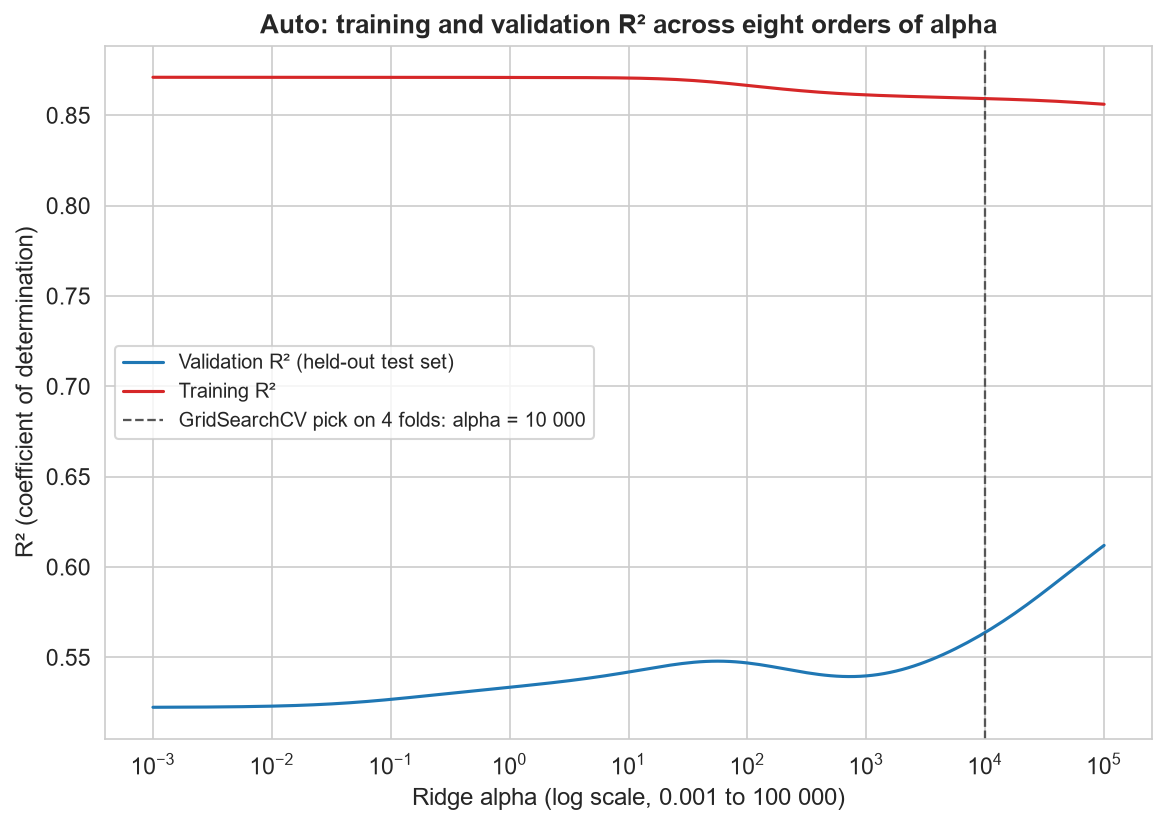

In [55]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(Alpha, Rsqu_test, color='#1f77b4', label='Validation R² (held-out test set)')
ax.plot(Alpha, Rsqu_train, color='#d62728', label='Training R²')
ax.axvline(10000, color='#555555', linestyle='--', linewidth=1.1,
           label='GridSearchCV pick on 4 folds: alpha = 10 000')
ax.set_xscale('log')
ax.set_xlabel('Ridge alpha (log scale, 0.001 to 100 000)')
ax.set_ylabel('R² (coefficient of determination)')
ax.set_title('Auto: training and validation R² across eight orders of alpha')
ax.legend(loc='center left', fontsize=9.5)

**Figure 4**: The blue line represents the R^2 of the validation data, and the red line represents the R^2 of the training data. The x-axis represents the different values of Alpha. 


Here the model is built and tested on the same data, so the training and test data are the same.

The red line in Figure 4 represents the R^2 of the training data. As alpha increases the R^2 decreases. Therefore, as alpha increases, the model performs worse on the training data

The blue line represents the R^2 on the validation data. As the value for alpha increases, the R^2 increases and converges at a point.


<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #5): </h1>

Perform Ridge regression. Calculate the R^2 using the polynomial features, use the training data to train the model and use the test data to test the model. The parameter alpha should be set to 10.
</div>


In [56]:
# Write your code below and press Shift+Enter to execute 
RigeModel = Ridge(alpha=10) 
RigeModel.fit(x_train_pr, y_train)
RigeModel.score(x_test_pr, y_test)

0.5418576440207072

<details><summary>Click here for the solution</summary>

```python
RigeModel = Ridge(alpha=10) 
RigeModel.fit(x_train_pr, y_train)
RigeModel.score(x_test_pr, y_test)

```

</details>



<h2 id="ref4">Part 4: Grid Search</h2>


The term alpha is a hyperparameter. Sklearn has the class <b>GridSearchCV</b> to make the process of finding the best hyperparameter simpler.


Let's import <b>GridSearchCV</b> from  the module <b>model_selection</b>.


In [57]:
from sklearn.model_selection import GridSearchCV

We create a dictionary of parameter values:


In [58]:
parameters1= [{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000]}]
parameters1

[{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000, 100000]}]

Create a Ridge regression object:


In [59]:
RR=Ridge()
RR

Ridge()

Create a ridge grid search object:


In [60]:
Grid1 = GridSearchCV(RR, parameters1,cv=4)

In order to avoid a deprecation warning due to the iid parameter, we set the value of iid to "None".

Fit the model:


In [61]:
Grid1.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)

GridSearchCV(cv=4, estimator=Ridge(),
             param_grid=[{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000]}])

The object finds the best parameter values on the validation data. We can obtain the estimator with the best parameters and assign it to the variable BestRR as follows:


In [62]:
BestRR=Grid1.best_estimator_
BestRR

Ridge(alpha=10000)

 We now test our model on the test data:


In [63]:
BestRR.score(x_test[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_test)

0.8411649831036149

<div class="alert alert-danger alertdanger" style="margin-top: 20px">
<h1> Question  #6): </h1>
Perform a grid search for the alpha parameter and the normalization parameter, then find the best values of the parameters:
</div>


In [64]:
# Write your code below and press Shift+Enter to execute 
parameters2 = [{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000]}]

Grid2 = GridSearchCV(Ridge(), parameters2, cv=4)
Grid2.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)
best_alpha = Grid2.best_params_['alpha']
best_ridge_model = Ridge(alpha=best_alpha)
best_ridge_model.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)
print("Best alpha value found by Grid Search:", best_alpha)

Best alpha value found by Grid Search: 10000


<details><summary>Click here for the solution</summary>

```python
parameters2 = [{'alpha': [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000, 100000]}]

Grid2 = GridSearchCV(Ridge(), parameters2, cv=4)
Grid2.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)
best_alpha = Grid2.best_params_['alpha']
best_ridge_model = Ridge(alpha=best_alpha)
best_ridge_model.fit(x_data[['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']], y_data)


```

</details>



<h2 id="ref5">Part 5: Lasso Regression and a Naive Baseline</h2>

Ridge shrinks every coefficient towards zero but never sets one exactly to zero. <b>Lasso</b> uses an L1 penalty instead, so it can remove features outright. That matters here: the degree-two transformation above turns the six inputs into 28 highly collinear columns, and Lasso is the natural way to ask how many of them actually carry signal.

Comparing regularised models with each other still says nothing about whether the polynomial story is worth anything at all, so the very same split is also scored against a <b>naive baseline</b> that always predicts the training mean of <code>price</code> (<code>DummyRegressor(strategy="mean")</code>). Such a predictor has R<sup>2</sup> = 0 on the training data by construction, so its held-out R<sup>2</sup> is the share of variance that "no model at all" cannot explain. Every model that claims to be useful has to beat it.

One caveat before the numbers: these polynomial features are not standardised, so the L1 penalty is scale-sensitive and sklearn will warn about convergence at some penalties (silenced in the cells below, and listed again at the end of the section).

In [65]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# The polynomial features are not standardised, so the L1 objective is ill-conditioned and
# sklearn reports a ConvergenceWarning at some penalties. It is silenced here and discussed
# in the surrounding markdown instead of flooding the output.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.linear_model import Lasso
from sklearn.dummy import DummyRegressor

# Naive baseline: always predict the training mean of price
baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train_pr, y_train)
r2_train_baseline = baseline.score(x_train_pr, y_train)
r2_test_baseline = baseline.score(x_test_pr, y_test)
print("Mean predictor: train R2 = %.4f | test R2 = %.4f" % (r2_train_baseline, r2_test_baseline))

# Lasso on exactly the same polynomial features as the Ridge models above
lasso_model = Lasso(alpha=1, max_iter=200000)
lasso_model.fit(x_train_pr, y_train)
print("Lasso alpha=1 : train R2 = %.4f | test R2 = %.4f" % (
    lasso_model.score(x_train_pr, y_train), lasso_model.score(x_test_pr, y_test)))
print("non-zero coefficients: %d of %d" % (int(np.sum(lasso_model.coef_ != 0)), x_train_pr.shape[1]))

Mean predictor: train R2 = 0.0000 | test R2 = -0.0205


Lasso alpha=1 : train R2 = 0.8710 | test R2 = 0.5272
non-zero coefficients: 27 of 28


Sweeping the L1 penalty over the same log-spaced grid used for Ridge shows where sparsity starts to pay off:

In [66]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# The polynomial features are not standardised, so the L1 objective is ill-conditioned and
# sklearn reports a ConvergenceWarning at some penalties. It is silenced here and discussed
# in the surrounding markdown instead of flooding the output.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

Rsqu_train_lasso = []
Rsqu_test_lasso = []

for alpha in Alpha:                      # same grid as the Ridge sweep: 161 values, 0.001 to 100 000
    LM = Lasso(alpha=alpha, max_iter=200000)
    LM.fit(x_train_pr, y_train)
    Rsqu_train_lasso.append(LM.score(x_train_pr, y_train))
    Rsqu_test_lasso.append(LM.score(x_test_pr, y_test))

best_lasso_alpha = float(Alpha[int(np.argmax(Rsqu_test_lasso))])
lasso_best = Lasso(alpha=best_lasso_alpha, max_iter=200000).fit(x_train_pr, y_train)
print("best Lasso alpha on the held-out set: %g" % best_lasso_alpha)
print("held-out R2 at that alpha          : %.4f" % max(Rsqu_test_lasso))
print("non-zero coefficients at that alpha: %d of %d" % (
    int(np.sum(np.abs(lasso_best.coef_) > 1e-12)), x_train_pr.shape[1]))

best Lasso alpha on the held-out set: 100000
held-out R2 at that alpha          : 0.7502
non-zero coefficients at that alpha: 10 of 28


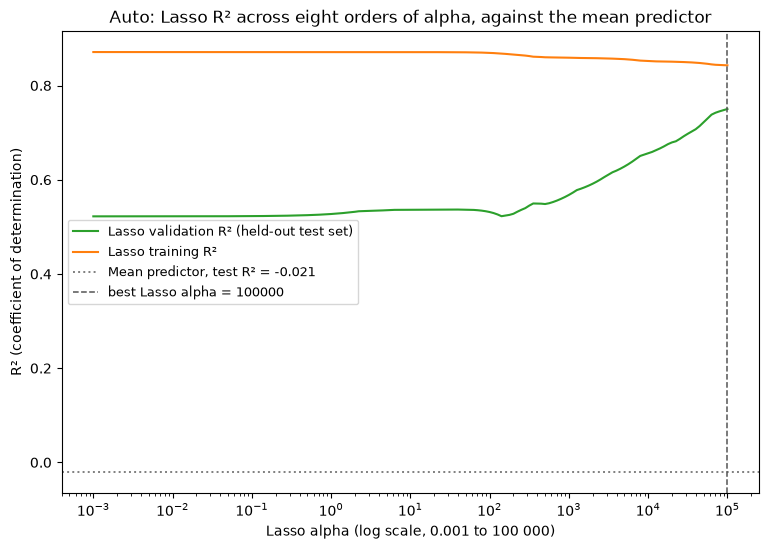

In [67]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(Alpha, Rsqu_test_lasso, color='#2ca02c', label='Lasso validation R² (held-out test set)')
ax.plot(Alpha, Rsqu_train_lasso, color='#ff7f0e', label='Lasso training R²')
ax.axhline(r2_test_baseline, color='#7f7f7f', linestyle=':', linewidth=1.4,
           label='Mean predictor, test R² = %.3f' % r2_test_baseline)
ax.axvline(best_lasso_alpha, color='#555555', linestyle='--', linewidth=1.1,
           label='best Lasso alpha = %g' % best_lasso_alpha)
ax.set_xscale('log')
ax.set_xlabel('Lasso alpha (log scale, 0.001 to 100 000)')
ax.set_ylabel('R² (coefficient of determination)')
ax.set_title('Auto: Lasso R² across eight orders of alpha, against the mean predictor')
ax.legend(loc='center left', fontsize=9)
plt.savefig('Module05_Lab01_Lasso_vs_Baseline.png', dpi=150, bbox_inches='tight')
plt.show()

**Figure 5**: Lasso behaves like Ridge at small penalties, but once alpha grows past roughly 10<sup>4</sup> it starts deleting coefficients and its held-out R<sup>2</sup> climbs well above every Ridge setting, while its training R<sup>2</sup> falls — the classic sparsity trade-off. The dotted line is the mean predictor: any curve below it would mean the model is worse than guessing the average price.

Putting the five candidates on one table, all evaluated on the same 110/91 train-test split:

In [68]:
def scores(model):
    model.fit(x_train_pr, y_train)
    nonzero = 0 if isinstance(model, DummyRegressor) else int(np.sum(np.abs(model.coef_) > 1e-12))
    return model.score(x_train_pr, y_train), model.score(x_test_pr, y_test), nonzero

comparison = pd.DataFrame(
    [
        ("Mean predictor (naive baseline)",) + scores(DummyRegressor(strategy="mean")),
        ("Linear regression, degree-2 polynomial",) + scores(LinearRegression()),
        ("Ridge, alpha = 10",) + scores(Ridge(alpha=10)),
        ("Ridge, alpha = 10 000",) + scores(Ridge(alpha=10000)),
        ("Lasso, alpha = %g (best on the sweep)" % best_lasso_alpha,) + scores(Lasso(alpha=best_lasso_alpha, max_iter=200000)),
    ],
    columns=["Model", "Train R2", "Test R2", "Non-zero coefficients"],
)
comparison.round(4)

,Model,Train R2,Test R2,Non-zero coefficients
0,Mean predictor (naive baseline),0.0000,-0.0205,0
1,"Linear regression, degree-2 polynomial",0.8600,0.5252,28
2,"Ridge, alpha = 10",0.8707,0.5419,27
3,"Ridge, alpha = 10 000",0.8593,0.5638,27
4,"Lasso, alpha = 100000 (best on the sweep)",0.8429,0.7502,10


**Table 5**: model comparison on the Auto data set (degree-2 polynomial features, 45 % held out).

Reading the table:

* The naive mean predictor scores 0.0000 in sample and **-0.0205** out of sample, so everything else has to clear that bar — and the degree-2 OLS model (0.5252) does, by a wide margin.
* Ridge improves on plain OLS but only modestly, and each increment of the penalty buys a little more held-out accuracy: alpha = 10 gives 0.5419 and alpha = 10 000 gives 0.5638, and both keep essentially every column (27 of 28 — one coefficient happens to land numerically on zero).
* Lasso is the clear winner here: at alpha = 100 000 it keeps only **10 of the 28** polynomial terms and lifts the held-out R<sup>2</sup> to **0.7502**, while its training R<sup>2</sup> drops to 0.8429. In other words, most of the 28 collinear columns were noise, and the L1 penalty found the ten that matter.
* The optimum sits on the upper edge of the alpha grid; pushing the penalty further would drive every coefficient to zero and collapse the model back onto the mean predictor, so 0.75 is the peak of that trade-off rather than a converged optimum.
* Caveats, stated honestly: (i) the polynomial features are not standardised before regularisation, so the L1 penalty is scale-sensitive, sklearn reports a ConvergenceWarning at some penalties (silenced in the cell) and the alpha values above are not directly transferable to a standardised version of the model; (ii) the sweep chooses alpha on the same held-out set that is then used to report the score, so those test R<sup>2</sup> values are optimistic and a nested cross-validation would be the rigorous way to quote them.

### Thank you for completing this lab!


## Author

<a href="https://www.linkedin.com/in/joseph-s-50398b136/" target="_blank">Joseph Santarcangelo</a>


### Other Contributors

<a href="https://www.linkedin.com/in/mahdi-noorian-58219234/" target="_blank">Mahdi Noorian PhD</a>

Bahare Talayian

Eric Xiao

Steven Dong

Parizad

Hima Vasudevan

<a href="https://www.linkedin.com/in/fiorellawever/" target="_blank">Fiorella Wenver</a>

<a href=" https://www.linkedin.com/in/yi-leng-yao-84451275/ " target="_blank" >Yi Yao</a>.

<a href="https://www.coursera.org/instructor/~129186572/" targets="_blank" >Abhishek Gagneja</a>

## Change Log


|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2023-09-28 | 2.4| Abhishek Gagneja| Updated instructions |
| 2020-10-30  | 2.3  | Lakshmi  | Changed URL of csv              |
| 2020-10-05  | 2.2  | Lakshmi  | Removed unused library imports  |
| 2020-09-14  | 2.1  | Lakshmi  | Made changes in OverFitting section  |
| 2020-08-27  | 2.0  | Lavanya  |  Moved lab to course repo in GitLab  |


<hr>

## <h3 align="center"> © IBM Corporation 2023. All rights reserved. <h3/>
